##### Feladat

Határozzuk meg az igénybevételi függvényeket és rajzoljuk fel az igénybevételi ábrákat!

<img src="img/01.jpg" alt="Feladat" width=350px>

##### Csomagok importálása

In [1]:
import numpy as np # Numerikus számítások
import matplotlib.pyplot as plt # Ábrázolás
plt.rcParams['mathtext.fontset'] = 'cm' # Betűtípus az ábrákon
plt.rcParams['font.family'] = 'serif' # Betűtípus az ábrákon
plt.rcParams['font.serif'] = ['cmr10'] # Betűtípus az ábrákon
plt.rcParams['axes.formatter.use_mathtext'] = True # Betűtípus az ábrákon
plt.rcParams['axes.unicode_minus'] = False # Betűtípus az ábrákon
from IPython.display import display, Math, Latex # Szép kimenet Jupyter notebookban
import sympy as sp # Szimbólikus számítások
from sympy import latex # Szép kimenet Jupyter notebookban
sp.init_printing() # Szép kimenet Jupyter notebookban

##### Adatok

In [2]:
# A feladat paraméteresen adott, így az adatokat szimbólumként vesszük fel
L, F_1 = sp.symbols('L, F_1', positive=True)

# Rúdirányú koordináta
x = sp.symbols('x')

##### Igénybevételek

Igénybevétel: egy rúd adott keresztmetszetét érő erőhatás.

<img src="img/02.jpg" alt="Feladat" width=600px>

* $K$ terhelése balról: a balról elhagyott rész hatása (redukáltja) a keresztmetszet súlypontjába.

* $K$ terhelése jobbról: a jobbról elhagyott rész hatása (redukáltja) a keresztmetszet súlypontjába.

Komponensek:

* erő: $\mathbf{F} = \mathbf{N} + \mathbf{V}$

    * $\mathbf{N}$: normálerő (rúdirányú)

    * $\mathbf{V}$: nyíróerő (rúdra merőleges)

* nyomaték: $\mathbf{M} = \mathbf{M}_h + \mathbf{M}_t$

    * $\mathbf{M}_h$: hajlítónyomaték (rúdra merőleges)

    * $\mathbf{M}_t$: csavarónyomaték (rúdirányú)

##### Előjelkonvenció

<img src="img/03.jpg" alt="Feladat" width=350px>

A balról és a jobbról elhagyott rész redukáltja egymás ellentettje (a rúd egyensúlyban van), így az előjelkonvenció miatt mindkét oldalról ugyanazokat az igénybevételeket kapjuk.

##### Igénybevételi függvények

<img src="img/04.jpg" alt="Feladat" width=350px>

* rúdirányú koordináta: $x$

* minden $x$ keresztmetszetre ($x \in [0, L]$) felírjuk az igénybevételeket → $x$ függő függvények: $N(x)$, $V(x)$, $M_h(x)$, $M_t(x)$

* ha van megoszló terhelés: $V'(x) = p(x)$

* nyíróerő és hajlítónyomaték kapcsolata: $M_h'(x) = -V(x)$

##### Szabadtest ábra

A teljes erőrendszert ismerni kell azon az oldalon, ahonnan felírjuk a függvényeket! Itt balról írjuk fel a függvényeket, ezért először a reakciókat határozzuk meg.

<img src="img/05.jpg" alt="Feladat" width=300px>

##### A reakciók

In [3]:
A_x, A_y, M_A = sp.symbols('A_x, A_y, M_A')

##### Egyensúlyi egyenletek

In [4]:
# x irányú erő egyensúly
eq1 = -A_x + F_1
display(Math(rf'\sum F_x = 0 \quad \longrightarrow \quad {latex(eq1)} = 0 \qquad (1)'))

# y irányú erő egyensúly
eq2 = A_y
display(Math(rf'\sum F_y = 0 \quad \longrightarrow \quad {latex(eq2)} = 0 \qquad (2)'))

# z irányú nyomatéki egyensúly az A pontra
eq3 = M_A
display(Math(rf'\sum M_A = 0 \quad \longrightarrow \quad {latex(eq3)} = 0 \qquad (3)'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Egyensúlyi egyenletek megoldása

In [5]:
sol = sp.solve([eq1, eq2, eq3], [A_x, A_y, M_A])

A_xsol = sol[A_x]
display(Math(rf'A_x = {latex(A_xsol)}'))

A_ysol = sol[A_y]
display(Math(rf'A_y = {latex(A_ysol)}'))

M_Asol = sol[M_A]
display(Math(rf'M_A = {latex(M_Asol)}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Redukálás a $K$ keresztmetszetbe

Balról redukálunk: a $K$ keresztmetszettől balra lévő részen csak az $A_x$ reakcióerő hat ($A_y = 0$, $M_A = 0$), ezt redukáljuk a $K$ keresztmetszet súlypontjába.

<img src="img/06.jpg" alt="Feladat" width=320px>

##### Az igénybevételi függvények

In [6]:
# Normálerő: az A_x erő balra mutat, ami balról nézve pozitív (előjelkonvenció)
N = A_xsol
display(Math(rf'N(x) = A_x = {latex(N)}'))

# Nyíróerő: nincs rúdra merőleges erő
V = sp.Integer(0)
display(Math(rf'V(x) = {latex(V)}'))

# Hajlítónyomaték: az A_x hatásvonala átmegy a K keresztmetszet súlypontján
M_h = sp.Integer(0)
display(Math(rf'M_h(x) = {latex(M_h)}'))

# Csavarónyomaték: nincs rúdirányú nyomaték
M_t = sp.Integer(0)
display(Math(rf'M_t(x) = {latex(M_t)}'))

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

##### Ellenőrzés

Jobbról redukálva ugyanezt kell kapnunk: a $K$ keresztmetszettől jobbra lévő részen csak az $F_1$ erő hat.

In [7]:
# Normálerő jobbról: az F_1 erő jobbra mutat, ami jobbról nézve pozitív
N_jobb = F_1
display(Math(rf'N(x) = {latex(N_jobb)}'))

<IPython.core.display.Math object>

Látható, hogy ugyanazt az eredményt kaptuk.

##### Ábrázolva

Az ábrázoláshoz számértékeket kell helyettesíteni. Az $L = 1$ és $F_1 = 1$ helyettesítéssel a függvények alakja nem változik, a tengelyeken pedig a jellemző értékeket szimbolikusan jelöljük.

In [8]:
def igenybeveteli_abra(ax, f, x_0, x_1, felirat, szin='red'):
    # A függvény kiértékelése numerikusan az [x_0, x_1] tartományon
    x_vals = np.linspace(x_0, x_1, 201)
    f_vals = sp.lambdify(x, f, 'numpy')(x_vals) * np.ones_like(x_vals) # Konstans függvény esetén is tömböt kapunk
    # A függvény görbéje (zorder: az x tengely fölé rajzoljuk)
    ax.plot(x_vals, f_vals, color=szin, lw=1.5, zorder=3)
    # Satírozás a görbe és az x tengely között (mint a kézi rajzokon)
    ax.vlines(x_vals[::10], 0, f_vals[::10], color=szin, lw=0.8)
    # Lezárás a tartomány két végén
    ax.vlines([x_0, x_1], 0, [f_vals[0], f_vals[-1]], color=szin, lw=1.5, zorder=3)
    # Az x tengely
    ax.axhline(0, color='black', lw=1)
    ax.set_ylabel(felirat)
    ax.grid(True, alpha=0.5)

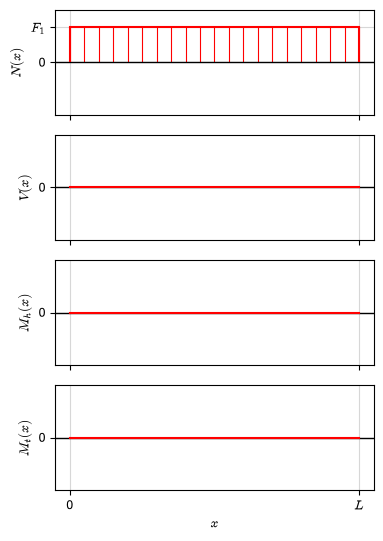

In [9]:
# Számértékek helyettesítése az ábrázoláshoz
ertekek = {L: 1, F_1: 1}

fig, axs = plt.subplots(4, 1, figsize=(10/2.54, 14/2.54), sharex=True)
igenybeveteli_abra(axs[0], N.subs(ertekek), 0, 1, r'$N(x)$')
igenybeveteli_abra(axs[1], V.subs(ertekek), 0, 1, r'$V(x)$')
igenybeveteli_abra(axs[2], M_h.subs(ertekek), 0, 1, r'$M_h(x)$')
igenybeveteli_abra(axs[3], M_t.subs(ertekek), 0, 1, r'$M_t(x)$')

# A jellemző értékek a tengelyeken
axs[0].set_yticks([0, 1], [r'$0$', r'$F_1$'])
axs[1].set_yticks([0], [r'$0$'])
axs[2].set_yticks([0], [r'$0$'])
axs[3].set_yticks([0], [r'$0$'])
axs[3].set_xticks([0, 1], [r'$0$', r'$L$'])
axs[3].set_xlabel(r'$x$')
for ax in axs:
    ax.set_ylim(-1.5, 1.5)
plt.tight_layout()
plt.savefig('igenybeveteli_fuggvenyek.pdf') # Az ábra mentése PDF dokumentumba
plt.show()